<a href="https://colab.research.google.com/github/marrihruthika28/Deep-Learning/blob/main/CO_1_DL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import sys

print("Python Version:", sys.version)


Python Version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [ ]:

!pip install -q ultralytics


In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from ultralytics import YOLO

print("OpenCV Version:", cv2.__version__)
print("NumPy Version:", np.__version__)
print("All libraries imported successfully!")


OpenCV Version: 5.0.0
NumPy Version: 2.4.6
All libraries imported successfully!


Task-2 and 3

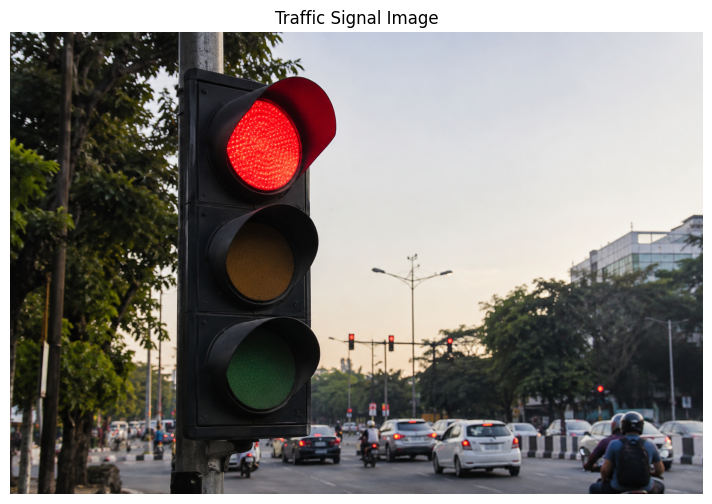

In [ ]:
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('/content/traffic_signal.jpg')
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,6))
plt.imshow(image)
plt.title("Traffic Signal Image")
plt.axis("off")
plt.show()


Task - 4

In [ ]:

import cv2
from IPython.display import Video, display
import os

video_path = "/content/traffic_vedio.mp4"

if os.path.exists(video_path):
    cap = cv2.VideoCapture(video_path)

    print("Video loaded:", cap.isOpened())
    print("FPS:", cap.get(cv2.CAP_PROP_FPS))
    print("Total Frames:", int(cap.get(cv2.CAP_PROP_FRAME_COUNT)))

    cap.release()

    display(Video(video_path, embed=True, width=700))
else:
    print("Video file not found. Check the filename!")


Task-5

In [ ]:

import cv2
import os

video_path = "/content/traffic_vedio.mp4"

cap = cv2.VideoCapture(video_path)

# Create folder to store frames
os.makedirs("/content/traffic_frames", exist_ok=True)

frame_count = 0
saved_count = 0

while True:
    ret, frame = cap.read()

    if not ret:
        break

    # Extract every 30th frame
    if frame_count % 30 == 0:
        filename = f"/content/traffic_frames/frame_{saved_count}.jpg"
        cv2.imwrite(filename, frame)
        saved_count += 1

    frame_count += 1

cap.release()

print("Total video frames:", frame_count)
print("Extracted frames:", saved_count)
print("Frames saved successfully!")


Total video frames: 941
Extracted frames: 32
Frames saved successfully!


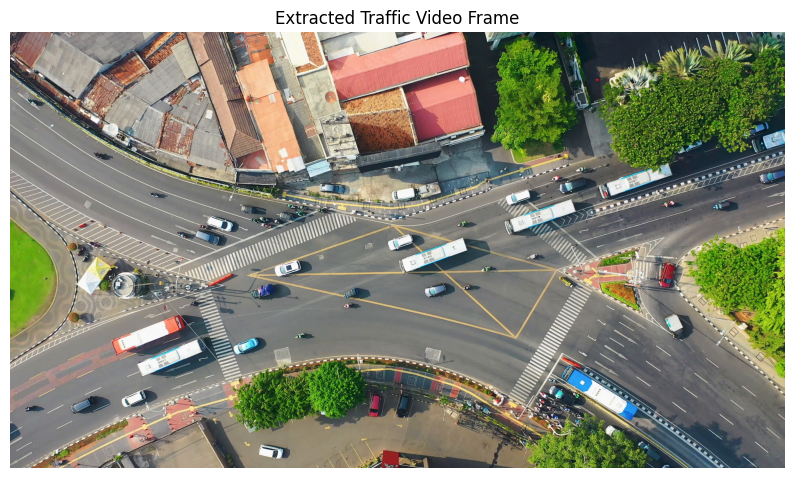

In [ ]:

import matplotlib.pyplot as plt

image = cv2.imread("/content/traffic_frames/frame_0.jpg")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10,6))
plt.imshow(image)
plt.title("Extracted Traffic Video Frame")
plt.axis("off")
plt.show()


Task-6

In [ ]:

!pip install ultralytics


In [ ]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load pretrained YOLO model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


YOLO model loaded successfully!


In [ ]:

video_path = "/content/traffic_vedio.mp4"

# COCO class ID 2 represents cars
results = model.predict(
    source=video_path,
    classes=[2],
    conf=0.25,
    save=True,
    project="/content",
    name="Task6_Car_Detection",
    exist_ok=True
)

print("Car detection completed successfully!")



WARNING ⚠️ 
Inference results will accumulate in RAM unless `stream=True` is passed, which can cause out-of-memory errors for large
sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/1403) /content/traffic_vedio.mp4: 384x640 5 cars, 398.8ms
video 1/1 (frame 2/1403) /content/traffic_vedio.mp4: 384x640 5 cars, 249.9ms
video 1/1 (frame 3/1403) /content/traffic_vedio.mp4: 384x640 4 cars, 138.4ms
video 1/1 (frame 4/1403) /content/traffic_vedio.mp4: 384x640 4 cars, 160.1ms
video 1/1 (frame 5/1403) /content/traffic_vedio.mp4: 384x640 5 cars, 137.6ms
video 1/1 (frame 6/1403) /content/traffic_vedio.mp4: 384x640 4 cars, 151.8

In [ ]:

# Read the first detected frame
result = model.predict(
    source="/content/traffic_frames/frame_0.jpg",
    classes=[2],
    conf=0.25
)

# Display detected image
annotated_image = result[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB))
plt.title("YOLO Car Detection")
plt.axis("off")
plt.show()


In [ ]:

import glob
from IPython.display import Video, display

output_files = glob.glob(
    "/content/Task6_Car_Detection/*.mp4"
)

print("Generated files:", output_files)

if output_files:
    display(Video(output_files[0], embed=True, width=700))
else:
    print("Check the Task6_Car_Detection folder for output.")


Task-7

In [ ]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


In [ ]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

# Load YOLO model
model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")

# Traffic video path
video_path = "/content/traffic_vedio.mp4"

# Detect cars, motorcycles, buses and trucks
results = model.predict(
    source=video_path,
    classes=[2, 3, 5, 7],
    conf=0.25,
    save=True,
    project="/content",
    name="Task7_Vehicle_Detection",
    exist_ok=True
)

print("Multiple vehicle detection completed!")


In [ ]:

import cv2
import matplotlib.pyplot as plt

image = cv2.imread("/content/traffic_frames/frame_0.jpg")

result = model.predict(
    source=image,
    classes=[2, 3, 5, 7],
    conf=0.25
)

annotated = result[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Multiple Vehicle Detection")
plt.axis("off")
plt.show()


Task-8

In [ ]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

print("YOLO model ready!")


In [ ]:

image_path = "/content/traffic_frames/frame_0.jpg"

image = cv2.imread(image_path)

results = model.predict(
    source=image,
    classes=[2, 3, 5, 7],
    conf=0.25
)

# Display vehicle names and confidence scores
for result in results:
    for box in result.boxes:
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])

        vehicle_name = model.names[class_id]

        print(
            f"Vehicle: {vehicle_name} | "
            f"Confidence: {confidence * 100:.2f}%"
        )


In [ ]:

annotated_image = results[0].plot()

plt.figure(figsize=(12, 7))
plt.imshow(
    cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
)

plt.title("Vehicle Detection with Confidence Scores")
plt.axis("off")
plt.show()


Task-9

In [ ]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


In [ ]:

image_path = "/content/traffic_frames/frame_0.jpg"

image = cv2.imread(image_path)

results = model.predict(
    source=image,
    classes=[2, 3, 5, 7],
    conf=0.25
)

# Initialize vehicle counts
vehicle_counts = {
    "car": 0,
    "motorcycle": 0,
    "bus": 0,
    "truck": 0
}

# Count detected vehicles
for box in results[0].boxes:
    class_id = int(box.cls[0])
    vehicle_name = model.names[class_id]

    if vehicle_name in vehicle_counts:
        vehicle_counts[vehicle_name] += 1

# Display counts
print("VEHICLE COUNT REPORT")

for vehicle, count in vehicle_counts.items():
    print(vehicle, ":", count)

total = sum(vehicle_counts.values())

print("----------------------")
print("Total Vehicles:", total)


In [ ]:

annotated = results[0].plot()

count_text = f"Total Vehicles: {total}"

cv2.putText(
    annotated,
    count_text,
    (20, 40),
    cv2.FONT_HERSHEY_SIMPLEX,
    1,
    (0, 255, 0),
    2
)

plt.figure(figsize=(12, 7))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Vehicle Counting System")
plt.axis("off")
plt.show()


Task-10

In [ ]:

# Calculate traffic density
if total <= 5:
    density = "Low Traffic"
elif total <= 15:
    density = "Medium Traffic"
else:
    density = "High Traffic"

print("Total Vehicles:", total)
print("Traffic Density:", density)


In [ ]:

plt.figure(figsize=(7, 4))

plt.bar(
    ["Total Vehicles"],
    [total]
)

plt.title("Traffic Density Analysis")
plt.ylabel("Number of Vehicles")

plt.show()

print("Traffic Status:", density)


In [ ]:
Task-11

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


In [ ]:

import cv2

video_path = "/content/traffic_vedio.mp4"

cap = cv2.VideoCapture(video_path)

vehicle_classes = [2, 3, 5, 7]

frame_number = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    # Process every 10th frame
    if frame_number % 10 == 0:

        results = model.predict(
            frame,
            classes=vehicle_classes,
            conf=0.25,
            verbose=False
        )

        vehicle_count = len(results[0].boxes)

        # Traffic classification
        if vehicle_count <= 5:
            traffic_status = "LOW TRAFFIC"
            alert = "No Congestion"

        elif vehicle_count <= 15:
            traffic_status = "MEDIUM TRAFFIC"
            alert = "Moderate Traffic"

        else:
            traffic_status = "HIGH TRAFFIC"
            alert = "CONGESTION ALERT!"

        # Draw vehicle detection boxes
        annotated = results[0].plot()

        # Display traffic status
        cv2.putText(
            annotated,
            traffic_status,
            (20, 40),
            cv2.FONT_HERSHEY_SIMPLEX,
            1,
            (0, 255, 0),
            2
        )

        cv2.putText(
            annotated,
            alert,
            (20, 80),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 0, 255),
            2
        )

        cv2.putText(
            annotated,
            f"Vehicles: {vehicle_count}",
            (20, 120),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 255, 0),
            2
        )

        cv2.imwrite(
            f"/content/congestion_frame_{frame_number}.jpg",
            annotated
        )

        print(
            "Frame:", frame_number,
            "| Vehicles:", vehicle_count,
            "| Status:", traffic_status,
            "| Alert:", alert
        )

    frame_number += 1

cap.release()

print("Traffic congestion analysis completed!")


In [ ]:

import glob
import matplotlib.pyplot as plt

files = sorted(
    glob.glob("/content/congestion_frame_*.jpg"),
    key=lambda x: int(x.split("_")[-1].split(".")[0])
)

if files:
    image = cv2.imread(files[0])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(12, 7))
    plt.imshow(image)
    plt.title("Traffic Congestion Detection")
    plt.axis("off")
    plt.show()
else:
    print("No congestion frames found!")


In [ ]:
task-12

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("YOLO tracking model loaded successfully!")


In [ ]:

import cv2
from ultralytics import YOLO

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

output_path = "/content/Task12_Vehicle_Tracking.mp4"

fourcc = cv2.VideoWriter_fourcc(*"mp4v")
out = cv2.VideoWriter(
    output_path, fourcc, fps, (width, height)
)

frame_count = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    # Track vehicles using ByteTrack
    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    # Draw bounding boxes and tracking IDs
    annotated_frame = results[0].plot()

    out.write(annotated_frame)

    frame_count += 1

cap.release()
out.release()

print("Vehicle tracking completed!")
print("Total frames processed:", frame_count)
print("Output saved:", output_path)


In [ ]:

from IPython.display import Video, display
import os

if os.path.exists("/content/Task12_Vehicle_Tracking.mp4"):
    display(
        Video(
            "/content/Task12_Vehicle_Tracking.mp4",
            embed=True,
            width=700
        )
    )
else:
    print("Tracking video not found!")


task-13

In [ ]:

from ultralytics import YOLO
import cv2
import math

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


In [ ]:

import cv2
import math
from ultralytics import YOLO

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

# Assumed calibration: metres represented by one pixel
# Replace with a measured/calibrated value for real estimates
meters_per_pixel = 0.05

previous_positions = {}

frame_number = 0

print("Starting vehicle speed estimation...")

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        tracker="bytetrack.yaml",
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    annotated = results[0].plot()

    if results[0].boxes.id is not None:

        boxes = results[0].boxes.xyxy.cpu().numpy()
        ids = results[0].boxes.id.cpu().numpy()

        for box, track_id in zip(boxes, ids):

            x1, y1, x2, y2 = box

            center_x = (x1 + x2) / 2
            center_y = (y1 + y2) / 2

            track_id = int(track_id)

            if track_id in previous_positions:

                old_x, old_y, old_frame = previous_positions[track_id]

                pixel_distance = math.sqrt(
                    (center_x - old_x)**2 +
                    (center_y - old_y)**2
                )

                elapsed_time = (frame_number - old_frame) / fps

                if elapsed_time > 0:

                    distance_meters = (
                        pixel_distance * meters_per_pixel
                    )

                    speed_mps = distance_meters / elapsed_time

                    speed_kmph = speed_mps * 3.6

                    cv2.putText(
                        annotated,
                        f"ID {track_id}: {speed_kmph:.1f} km/h",
                        (int(x1), max(20, int(y1)-10)),
                        cv2.FONT_HERSHEY_SIMPLEX,
                        0.6,
                        (0, 255, 0),
                        2
                    )

            previous_positions[track_id] = (
                center_x, center_y, frame_number
            )

    if frame_number % 30 == 0:
        print("Processed frame:", frame_number)

    frame_number += 1

cap.release()

print("Vehicle speed estimation completed!")


task-14

In [ ]:

import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV and NumPy imported successfully!")


In [ ]:

image = cv2.imread("/content/traffic_signal.jpg")

if image is None:
    print("Traffic signal image not found!")
else:
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.figure(figsize=(10, 6))
    plt.imshow(image_rgb)
    plt.title("Traffic Signal Image")
    plt.axis("off")
    plt.show()


In [ ]:

# Convert image from BGR to HSV
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Select the left-side traffic signal region
height, width = image.shape[:2]
roi = hsv[0:int(height * 0.70), 0:int(width * 0.40)]

# Define HSV color ranges
red_lower1 = np.array([0, 100, 100])
red_upper1 = np.array([10, 255, 255])

red_lower2 = np.array([170, 100, 100])
red_upper2 = np.array([180, 255, 255])

yellow_lower = np.array([15, 100, 100])
yellow_upper = np.array([35, 255, 255])

green_lower = np.array([35, 80, 80])
green_upper = np.array([90, 255, 255])

# Create color masks
red_mask = (
    cv2.inRange(roi, red_lower1, red_upper1) |
    cv2.inRange(roi, red_lower2, red_upper2)
)

yellow_mask = cv2.inRange(
    roi, yellow_lower, yellow_upper
)

green_mask = cv2.inRange(
    roi, green_lower, green_upper
)

# Count pixels
red_pixels = cv2.countNonZero(red_mask)
yellow_pixels = cv2.countNonZero(yellow_mask)
green_pixels = cv2.countNonZero(green_mask)

print("Red pixels:", red_pixels)
print("Yellow pixels:", yellow_pixels)
print("Green pixels:", green_pixels)

# Identify dominant signal color
scores = {
    "RED": red_pixels,
    "YELLOW": yellow_pixels,
    "GREEN": green_pixels
}

detected_color = max(scores, key=scores.get)

if scores[detected_color] < 20:
    detected_color = "SIGNAL NOT DETECTED"

print("--------------------------------")
print("TRAFFIC SIGNAL STATUS:", detected_color)


In [ ]:

plt.figure(figsize=(8, 5))

plt.imshow(
    cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
)

plt.title("Detected Traffic Signal: " + detected_color)
plt.axis("off")
plt.show()


task-15

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


In [ ]:

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)

previous_positions = {}
waiting_times = {}

frame_number = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        ids = boxes.id.cpu().numpy()
        coordinates = boxes.xyxy.cpu().numpy()

        for box, track_id in zip(coordinates, ids):

            x1, y1, x2, y2 = box

            center_x = (x1 + x2) / 2
            center_y = (y1 + y2) / 2

            track_id = int(track_id)

            if track_id not in previous_positions:

                previous_positions[track_id] = (
                    center_x, center_y, frame_number
                )

                waiting_times[track_id] = 0

            else:

                old_x, old_y, start_frame = (
                    previous_positions[track_id]
                )

                movement = (
                    ((center_x - old_x)**2 +
                     (center_y - old_y)**2)**0.5
                )

                if movement < 3:
                    waiting_times[track_id] = (
                        waiting_times.get(track_id, 0) + 1/fps
                    )
                else:
                    waiting_times[track_id] = 0

                previous_positions[track_id] = (
                    center_x, center_y, frame_number
                )

    frame_number += 1

cap.release()

print("TRAFFIC WAITING TIME REPORT")

for track_id, waiting in waiting_times.items():
    print(
        f"Vehicle ID {track_id}: "
        f"{waiting:.2f} seconds"
    )

print("Waiting time analysis completed!")


task-16

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully!")


In [ ]:

import cv2
from ultralytics import YOLO

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

# Virtual counting line
line_x = width // 2

# Track previous vehicle positions
previous_positions = {}

# Avoid counting the same vehicle repeatedly
entered_ids = set()
exited_ids = set()

frame_number = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        classes=[2, 3, 5, 7],
        conf=0.25,
        tracker="bytetrack.yaml",
        verbose=False
    )

    annotated = results[0].plot()

    # Draw virtual counting line
    cv2.line(
        annotated,
        (line_x, 0),
        (line_x, height),
        (255, 0, 0),
        3
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        ids = boxes.id.cpu().numpy()
        coordinates = boxes.xyxy.cpu().numpy()

        for box, track_id in zip(coordinates, ids):

            x1, y1, x2, y2 = box

            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)

            track_id = int(track_id)

            if track_id in previous_positions:

                old_x = previous_positions[track_id]

                # Left to right = entering
                if old_x < line_x <= center_x:
                    entered_ids.add(track_id)

                # Right to left = leaving
                elif old_x > line_x >= center_x:
                    exited_ids.add(track_id)

            previous_positions[track_id] = center_x

            cv2.circle(
                annotated,
                (center_x, center_y),
                4,
                (0, 255, 255),
                -1
            )

    # Display counts
    cv2.putText(
        annotated,
        f"Entered: {len(entered_ids)}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (0, 255, 0),
        2
    )

    cv2.putText(
        annotated,
        f"Exited: {len(exited_ids)}",
        (20, 80),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.9,
        (0, 0, 255),
        2
    )

    if frame_number % 30 == 0:
        print(
            "Frame:", frame_number,
            "| Entered:", len(entered_ids),
            "| Exited:", len(exited_ids)
        )

    frame_number += 1

cap.release()

print("\nVEHICLE ENTRY AND EXIT REPORT")
print("Total vehicles entered:", len(entered_ids))
print("Total vehicles exited:", len(exited_ids))
print("Analysis completed!")


In [ ]:

import matplotlib.pyplot as plt

# Display the final counts
labels = ["Entered", "Exited"]
counts = [len(entered_ids), len(exited_ids)]

plt.figure(figsize=(7, 5))
plt.bar(labels, counts)

plt.title("Vehicle Entry and Exit Analysis")
plt.ylabel("Number of Vehicles")

for i, value in enumerate(counts):
    plt.text(i, value, str(value), ha="center")

plt.show()


task-17

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("Wrong-turn detection system initialized!")


In [ ]:

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

previous_positions = {}
wrong_turn_ids = set()

frame_number = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        classes=[2, 3, 5, 7],
        conf=0.25,
        verbose=False
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        ids = boxes.id.cpu().numpy()
        coordinates = boxes.xyxy.cpu().numpy()

        for box, track_id in zip(coordinates, ids):

            x1, y1, x2, y2 = box

            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)

            track_id = int(track_id)

            if track_id in previous_positions:

                old_x, old_y = previous_positions[track_id]

                # Demonstration rule:
                # Right-to-left movement is flagged
                if old_x - center_x > 5:
                    wrong_turn_ids.add(track_id)

            previous_positions[track_id] = (
                center_x, center_y
            )

    frame_number += 1

cap.release()

print("WRONG TURN ANALYSIS")
print("Vehicles flagged:", len(wrong_turn_ids))
print("Flagged vehicle IDs:", wrong_turn_ids)
print("Analysis completed!")


task-18

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("Wrong-way detection model loaded!")


In [ ]:

import cv2
from ultralytics import YOLO

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

output_path = "/content/Task18_Wrong_Way_Detection.mp4"

out = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

# Assume permitted traffic direction is left to right
expected_direction = "RIGHT"

previous_positions = {}
wrong_way_ids = set()

frame_number = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        classes=[2, 3, 5, 7],
        conf=0.25,
        tracker="bytetrack.yaml",
        verbose=False
    )

    annotated = results[0].plot()

    boxes = results[0].boxes

    if boxes.id is not None:

        ids = boxes.id.cpu().numpy()
        coordinates = boxes.xyxy.cpu().numpy()

        for box, track_id in zip(coordinates, ids):

            x1, y1, x2, y2 = box

            center_x = int((x1 + x2) / 2)
            center_y = int((y1 + y2) / 2)

            track_id = int(track_id)

            if track_id in previous_positions:

                old_x, old_y, old_frame = (
                    previous_positions[track_id]
                )

                # Check movement over multiple frames
                if frame_number - old_frame >= 10:

                    movement_x = center_x - old_x

                    if expected_direction == "RIGHT":
                        if movement_x < -10:
                            wrong_way_ids.add(track_id)

                    previous_positions[track_id] = (
                        center_x, center_y, frame_number
                    )

            else:
                previous_positions[track_id] = (
                    center_x, center_y, frame_number
                )

            if track_id in wrong_way_ids:

                cv2.putText(
                    annotated,
                    "WRONG WAY!",
                    (int(x1), max(25, int(y1)-10)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8,
                    (0, 0, 255),
                    2
                )

    cv2.putText(
        annotated,
        f"Wrong Way Vehicles: {len(wrong_way_ids)}",
        (20, 40),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.8,
        (0, 0, 255),
        2
    )

    out.write(annotated)

    frame_number += 1

cap.release()
out.release()

print("WRONG WAY DETECTION REPORT")
print("Vehicles flagged:", len(wrong_way_ids))
print("Vehicle IDs:", wrong_way_ids)
print("Analysis completed!")


In [ ]:

from IPython.display import Video, display

display(
    Video(
        "/content/Task18_Wrong_Way_Detection.mp4",
        embed=True,
        width=700
    )
)


task-19

In [ ]:

from ultralytics import YOLO
import cv2

model = YOLO("yolov8n.pt")

print("Illegal parking detection model loaded!")


In [ ]:

import cv2
from ultralytics import YOLO

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

# Define restricted parking area
zone_x1 = int(width * 0.35)
zone_y1 = int(height * 0.35)
zone_x2 = int(width * 0.70)
zone_y2 = int(height * 0.75)

# Track stationary vehicles
vehicle_positions = {}
stationary_frames = {}

restricted_ids = set()

frame_number = 0
fps = cap.get(cv2.CAP_PROP_FPS)

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.track(
        frame,
        persist=True,
        classes=[2, 3, 5, 7],
        conf=0.25,
        tracker="bytetrack.yaml",
        verbose=False
    )

    annotated = results[0].plot()

    # Draw restricted zone
    cv2.rectangle(
        annotated,
        (zone_x1, zone_y1),
        (zone_x2, zone_y2),
        (0, 0, 255),
        3
    )

    boxes = results[0].boxes

    if boxes.id is not None:

        ids = boxes.id.cpu().numpy()
        coordinates = boxes.xyxy.cpu().numpy()

        for box, track_id in zip(coordinates, ids):

            x1, y1, x2, y2 = box

            cx = int((x1 + x2) / 2)
            cy = int((y1 + y2) / 2)

            track_id = int(track_id)

            inside_zone = (
                zone_x1 <= cx <= zone_x2 and
                zone_y1 <= cy <= zone_y2
            )

            if track_id in vehicle_positions:

                old_x, old_y = vehicle_positions[track_id]

                movement = (
                    (cx-old_x)**2 + (cy-old_y)**2
                )**0.5

                if inside_zone and movement < 3:
                    stationary_frames[track_id] = (
                        stationary_frames.get(track_id, 0) + 1
                    )
                else:
                    stationary_frames[track_id] = 0

            else:
                stationary_frames[track_id] = 0

            vehicle_positions[track_id] = (cx, cy)

            # Alert after 5 seconds
            if stationary_frames[track_id] >= 5 * fps:
                restricted_ids.add(track_id)

                cv2.putText(
                    annotated,
                    "ILLEGAL PARKING ALERT!",
                    (cx, max(25, cy-20)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.7,
                    (0, 0, 255),
                    2
                )

    frame_number += 1

cap.release()

print("ILLEGAL PARKING REPORT")
print("Vehicles flagged:", len(restricted_ids))
print("Vehicle IDs:", restricted_ids)
print("Analysis completed!")


task-20

In [ ]:

from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolov8n.pt")

print("Triple-riding detection model loaded successfully!")


In [ ]:

import cv2
from ultralytics import YOLO

video_path = "/content/traffic_video.mp4"

cap = cv2.VideoCapture(video_path)

fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

output_path = "/content/Task20_Triple_Riding_Detection.mp4"

out = cv2.VideoWriter(
    output_path,
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (width, height)
)

frame_number = 0
alert_frames = 0

while cap.isOpened():

    ret, frame = cap.read()

    if not ret:
        break

    results = model.predict(
        frame,
        classes=[0, 3],  # 0 = Person, 3 = Motorcycle
        conf=0.30,
        verbose=False
    )

    people = []
    motorcycles = []

    for box in results[0].boxes:

        class_id = int(box.cls[0])
        x1, y1, x2, y2 = map(int, box.xyxy[0])

        if class_id == 0:
            people.append((x1, y1, x2, y2))

        elif class_id == 3:
            motorcycles.append((x1, y1, x2, y2))

    annotated = frame.copy()

    for bike in motorcycles:

        bx1, by1, bx2, by2 = bike

        bike_width = bx2 - bx1
        bike_height = by2 - by1

        # Expanded region around motorcycle
        rx1 = bx1 - int(bike_width * 0.25)
        ry1 = by1 - int(bike_height * 1.8)
        rx2 = bx2 + int(bike_width * 0.25)
        ry2 = by2 + int(bike_height * 0.3)

        rider_count = 0

        for person in people:

            px1, py1, px2, py2 = person

            # Person's bounding-box center
            pcx = (px1 + px2) // 2
            pcy = (py1 + py2) // 2

            if rx1 <= pcx <= rx2 and ry1 <= pcy <= ry2:
                rider_count += 1

                cv2.rectangle(
                    annotated,
                    (px1, py1),
                    (px2, py2),
                    (255, 255, 0),
                    2
                )

        # Draw motorcycle bounding box
        cv2.rectangle(
            annotated,
            (bx1, by1),
            (bx2, by2),
            (0, 255, 0),
            2
        )

        if rider_count > 2:
            label = f"TRIPLE RIDING ALERT: {rider_count} persons"
            color = (0, 0, 255)
            alert_frames += 1
        else:
            label = f"Persons detected: {rider_count}"
            color = (0, 255, 0)

        cv2.putText(
            annotated,
            label,
            (bx1, max(25, by1 - 10)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.6,
            color,
            2
        )

    out.write(annotated)
    frame_number += 1

cap.release()
out.release()

print("TRIPLE RIDING DETECTION REPORT")
print("Total frames processed:", frame_number)
print("Frames with triple-riding alerts:", alert_frames)
print("Output saved:", output_path)
print("Detection completed!")


In [ ]:

from IPython.display import Video, display

display(
    Video(
        "/content/Task20_Triple_Riding_Detection.mp4",
        embed=True,
        width=700
    )
)
